In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', '/Users/gracedavis/2026-10-19_before_submission_cleanup'))
BIAS = Path(os.environ.get('ASTRO320W_BIAS', '/Users/gracedavis/ASTRO 320W/04_Data/A/Bias_Frames'))


HR6200 distance [22.55698778 22.79093597 22.74645447] scale [1.24573371 1.23294629 1.23535736] mean 1.2380124539127282
HR7751 distance [166.45777701 166.34049098 166.49208661] scale [1.25256989 1.25345308 1.25231177] mean 1.2527782469251072
HR8815 distance [25.4216136  25.48993041 25.30557421] scale [1.28237336 1.27893641 1.28825372] mean 1.2831878266675258
HR7310 distance [65.05007228 65.40565248 65.40416545] scale [1.23597096 1.22925155 1.2292795 ] mean 1.2315006711367416
Mean scale and between-pair SEM: 1.2513697996605258 0.011502070538371758 FOV arcmin: 31.868217564688056


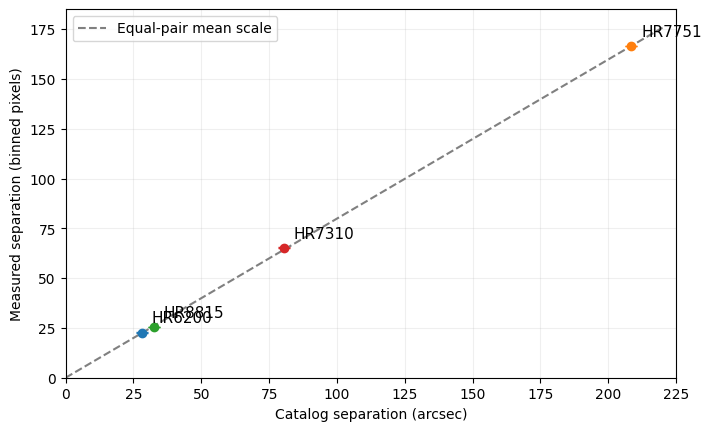

In [2]:
"""Calculate Exercise E distances and plot verified repeated pairs."""
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/astro320-mpl")
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import csv
folder=DATA
with (folder/"E_verified_repeats.csv").open() as f: rows=list(csv.DictReader(f))
means=[]
fig, ax=plt.subplots(figsize=(7,4.2),layout="constrained")
for name in dict.fromkeys(r["target"] for r in rows):
 r=[r for r in rows if r["target"]==name]
 d=np.array([np.hypot(float(t["x2"])-float(t["x1"]),float(t["y2"])-float(t["y1"])) for t in r])
 theta=float(r[0]["catalog_arcsec"]); scales=theta/d
 means.append(scales.mean())
 ax.errorbar(theta,d.mean(),yerr=d.std(ddof=1)/np.sqrt(len(d)),fmt="o",capsize=4)
 ax.annotate(name,(theta,d.mean()),xytext=(7,7),textcoords="offset points",fontsize=11)
 print(name,"distance",d,"scale",scales,"mean",scales.mean())
p=np.mean(means); error=np.std(means,ddof=1)/np.sqrt(len(means))
x=np.linspace(0,220,100);ax.plot(x,x/p,color="gray",ls="--",label="Equal-pair mean scale")
ax.set(xlabel="Catalog separation (arcsec)",ylabel="Measured separation (binned pixels)",xlim=(0,225),ylim=(0,185));ax.grid(alpha=.2);ax.legend(fontsize=10)
fig.savefig(OUT/"E_separation_pixels_vs_arcsec.pdf");fig.savefig(OUT/"E_separation_pixels_vs_arcsec.png",dpi=200)
print("Mean scale and between-pair SEM:",p,error,"FOV arcmin:",p*1528/60)


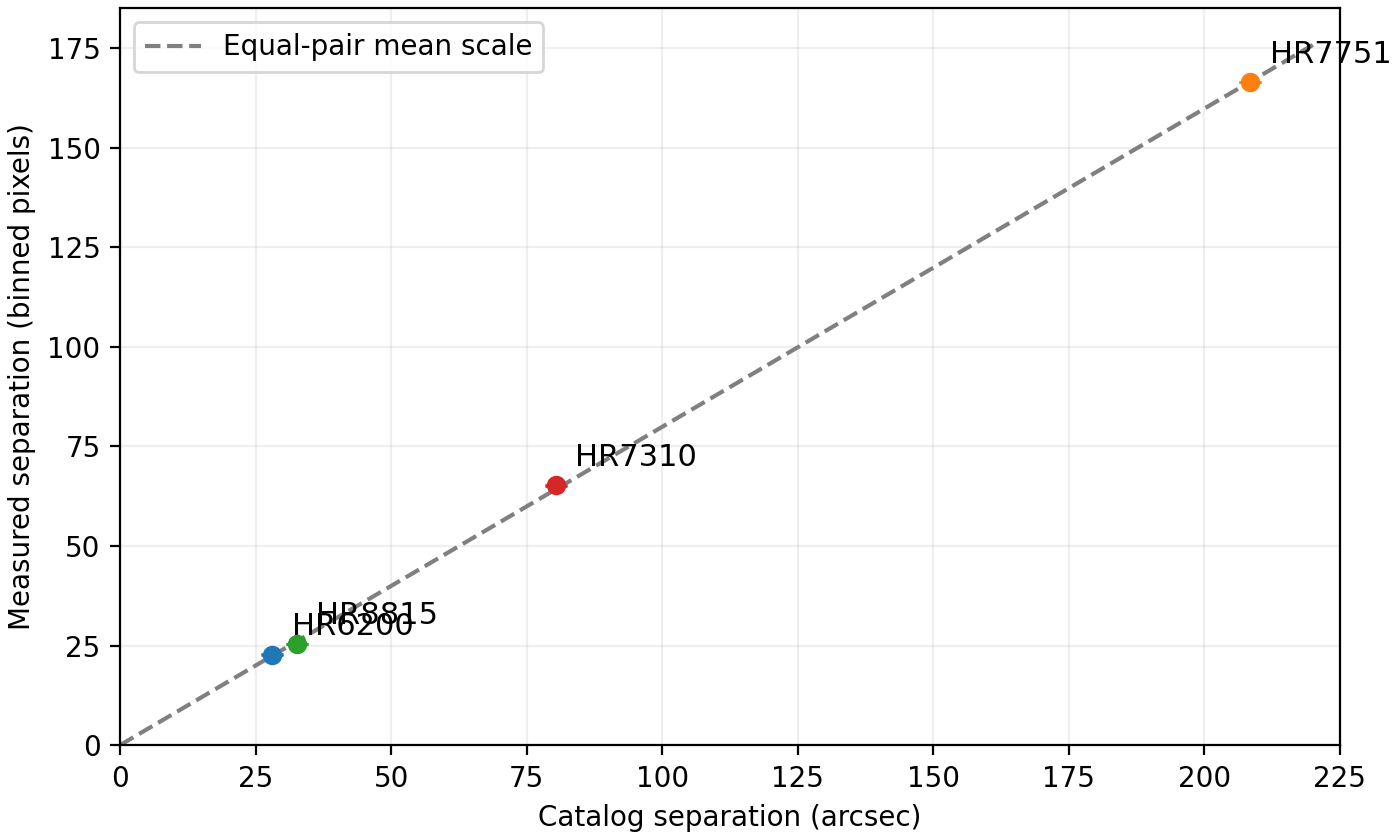

In [3]:
display(Image(filename=str(OUT/'E_separation_pixels_vs_arcsec.png')))